# Search: Solving a Maze Using a Goal-based Agent

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Formulate search problems using key components like initial state, actions, and goal state in a deterministic, fully observable environment.
* Implement and compare search algorithms including BFS, DFS, GBFS, A*, and IDS for planning paths through mazes.
* Analyze algorithm performance by measuring path cost, node expansions, depth, and memory usage across various maze types.
* Use visualization tools to represent maze paths and support debugging and analysis.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the notebook file and the completely rendered notebook with all outputs as a HTML file. 


## Introduction

In this exercise, we will implement the planning function for a type of goal-based agent called a __planning agent__. The planning function uses a map it is given to plan a path through the maze from the starting location $S$ to the goal location $G$. We will only focus on the planning function, so you do not need to implement an environment, just use the map to search for a path to solve the maze. 

Once the plan is made, the agent in a deterministic environment (i.e., the transition function is deterministic with the outcome of each state/action pair fixed and no randomness) can just follow the plan step-by-step and does not need to care about the percepts.
This is also called an **[open-loop system](https://en.wikipedia.org/wiki/Open-loop_controller).**
The execution phase is trivial and can be executed using a model-based reflex agent 
that ignores all percepts and just follows the plan. I will show you a short example, but you do not implement it in this exercise.

Given that the agent has a complete and correct map, the environment is **fully observable, discrete, deterministic, and known.** 
Remember:

* **Fully observable** means that the agent can see its state and what the available actions are. That means the **percepts contain the complete current state.**
Here, during planning, the agent always sees its x and y coordinates on the map and
also seeks when it has reached the goal state. 
* **Discrete** means that we have a **finite set of states.** The maze has a finite set 
of squares the agent can be in.
* **Deterministic** means that the **transition function contains no randomness.** An action in a state will always produce the same result. Going south from the start state always will lead to the same square.
* **Know** means that the agent **knows the complete transition function.** The 
agent has the map and therefore knows how its position changes when it walks in a direction.

Tree search algorithm implementations that you find online typically come from data structures courses and have a different aim than AI tree search. These algorithms assume that you already have a tree in memory. We are interested in dynamically creating a search tree with the aim of finding a good/the best path from the root note to the goal state. Follow the pseudo code presented in the text book (and replicated in the slides) closely. Ideally, we would like to search only a small part of the maze, i.e., create a search tree with as few nodes as possible. 

Several mazes for this exercise are stored as text files. We need to make sure that they are locally available.

In [39]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

In [40]:
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

base_url = "https://raw.githubusercontent.com/mhahsler/Introduction_to_Artificial_Intelligence/refs/heads/master/Search/"
download("maze_helper.py", base_url)

mazes = ["small_maze.txt", "medium_maze.txt", "large_maze.txt", "L_maze.txt", "empty_maze.txt", "empty_maze_2.txt", "loops_maze.txt", "open_maze.txt", ]
for maze in mazes:
    download(maze, base_url)

Here is the small example maze:

In [41]:
with open("small_maze.txt", "r") as f:
    maze_str = f.read()
print(maze_str)

XXXXXXXXXXXXXXXXXXXXXX
X XX        X X      X
X    XXXXXX X XXXXXX X
XXXXXX     S  X      X
X    X XXXXXX XX XXXXX
X XXXX X         X   X
X        XXX XXX   X X
XXXXXXXXXX    XXXXXX X
XG         XX        X
XXXXXXXXXXXXXXXXXXXXXX



**Note:** If you get an error here that the file cannot be found, then you need to download it. See [HOWTO Work on Assignments.](https://github.com/mhahsler/CS7320-AI/blob/master/HOWTOs/working_on_assignments.md)

## Parsing and pretty printing the maze

The maze can also be displayed in color using code in the module [maze_helper.py](maze_helper.py). The code parses the string representing the maze and converts it into a `numpy` 2d array which you can use in your implementation. Position are represented as a 2-tuple of the form `(row, col)`. 

In [42]:
import maze_helper as mh

maze = mh.parse_maze(maze_str)

# look at a position in the maze by subsetting the 2d array
print("Position(0,0):", maze[0, 0])

# there is also a helper function called `look(maze, pos)` available
# which uses a 2-tuple for the position.
print("Position(8,1):", mh.look(maze, (8, 1)))

Position(0,0): X
Position(8,1): G


A helper function to visualize the maze is also available.

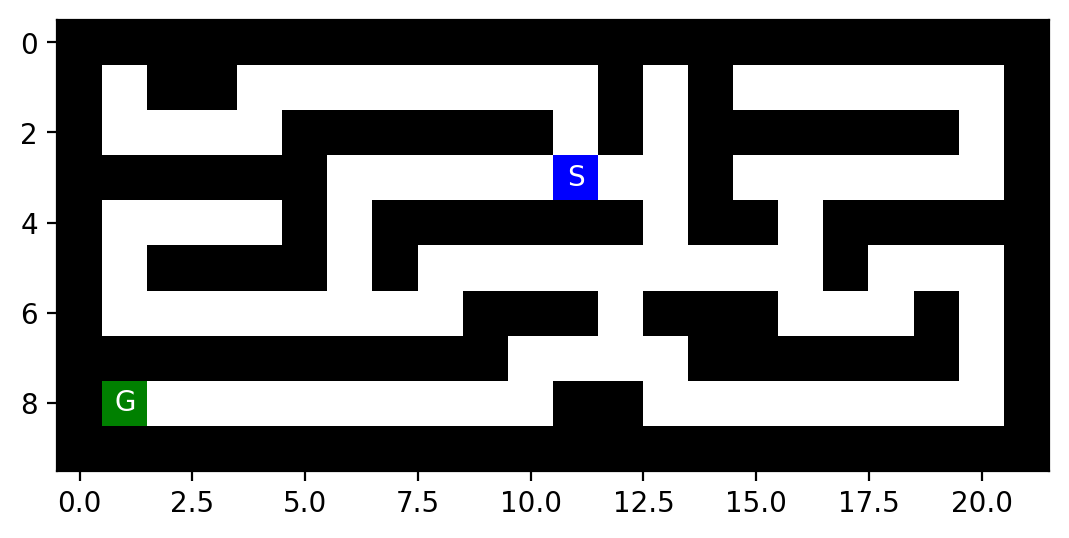

(<Figure size 640x480 with 1 Axes>, <Axes: >)

In [43]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
# use higher resolution images in notebooks

mh.show_maze(maze)

Find the `(x,y)` position of the start and the goal using the helper function `find_pos()`

In [44]:
print("Start location:", mh.find_pos(maze, what = "S"))
print("Goal location:", mh.find_pos(maze, what = "G"))

Start location: (np.int64(3), np.int64(11))
Goal location: (np.int64(8), np.int64(1))


Helper function documentation.

In [45]:
help(mh)

Help on module maze_helper:

NAME
    maze_helper

DESCRIPTION
    Code for the Maze Assignment
    Usage:
        import maze_helper as mh
        mh.show_some_mazes()

FUNCTIONS
    animate_maze(result, repeat=False)
        (Experimental) Build an animation from a list of mazes.

        Parameters:
            result: a list with the elements path, reached, actions and maze_anim with a list of maze arrays that contain what you want to visualize.
            repeat: if True, the animation will repeat.

    find_pos(maze, what='S')
        Find start/goal in a maze and returns the first one.
        Caution: there is no error checking!

        Parameters:
            maze: a array with characters produced by parse_maze()
            what: the letter to be found ('S' for start and 'G' for goal)

        Returns:
            a tupple (x, y) for the found position.

    look(maze, pos)
        Look at the label of a square with the position as an array of the form (x, y).

        Para

You will need to make a local copy of the module file [maze_helper.py](maze_helper.py) in the same folder where your notebook is.

## An Example for a Planning Agent

I will show you here how to implement a simple agent that uses a random plan. It will not solve the maze, but show you how the mechanics work.

First, we define a generic planning agent that fist plans, and then executes the plan step-by-step. 

In [46]:
class Planning_Agent:
    def __init__(self, maze, start, goal, planning_function):
        self.maze = maze
        self.start = start
        self.goal = goal
        self.planning_function = planning_function
        self.plan = None
        self.progress = None

    def act(self):
        # plan if no plan exists
        if self.plan is None:
            print("Planning...")
            self.plan = self.planning_function(self.maze, self.start, self.goal)
            self.progress = 0
        
        # check if plan is completed
        if self.progress >= len(self.plan):        
            raise Exception("Completed Plan. No more planned actions")
        
        # follow the plan
        action = self.plan[self.progress]
        print(f"Following plan... step {self.progress}: {action}")

        self.progress += 1
        return action

Next, we define the planning function. This function is what you will implement in this assignment.  

In [47]:
import numpy as np

def plan_random(maze, start, goal):
    """Create a random plan with 10 steps"""
    plan = np.random.choice(["N", "E", "S", "W"], size=10, replace=True).tolist()
    return plan

plan_random(maze, (1,1), (8,8))

['N', 'W', 'W', 'E', 'W', 'W', 'S', 'W', 'N', 'N']

This planning function is not great and will not produce a plan that solves the maze. Your planning functions will do better.

Finally, we can create the planning agent, give it the planning function and implement a simple environment that asks it 11 times for an action.

In [48]:
my_agent = Planning_Agent(maze, mh.find_pos(maze, what = "S"), mh.find_pos(maze, what = "G"), plan_random)

def environment(agent_function, steps):
    for _ in range(steps):
        try:
            agent_function()
        except Exception as e:
            print(f"Agent exception: {e}")

environment(my_agent.act, steps=11)

Planning...
Following plan... step 0: E
Following plan... step 1: E
Following plan... step 2: E
Following plan... step 3: W
Following plan... step 4: S
Following plan... step 5: N
Following plan... step 6: W
Following plan... step 7: S
Following plan... step 8: N
Following plan... step 9: N
Agent exception: Completed Plan. No more planned actions


Note: The agent and environment implementation above is just an illustration. You will only implement and experiment with different versions of the planning function.

## Tree structure

To use tree search, you will need to implement a tree data structure in Python. 
Here is an implementation of the basic node structure for the search algorithms (see Fig 3.7 on page 73). I have added a method that extracts the path from the root node to the current node. It can be used to get the path when the search is completed.

In [49]:
class Node:
    def __init__(self, pos, parent, action, cost):
        self.pos = tuple(pos)    # the state; positions are (row,col)
        self.parent = parent     # reference to parent node. None means root node.
        self.action = action     # action used in the transition function (root node has None)
        self.cost = cost         # for uniform cost this is the depth. It is also g(n) for A* search

    def __str__(self):
        return f"Node - pos = {self.pos}; action = {self.action}; cost = {self.cost}"
    
    def get_path_from_root(self):
        """returns nodes on the path from the root to the current node."""
        node = self
        path = [node]
    
        while not node.parent is None:
            node = node.parent
            path.append(node)
        
        path.reverse()
        
        return(path)

If needed, then you can add more fields to the class like the heuristic value $h(n)$ or $f(n)$.

Examples for how to create and use a tree and information on memory management can be found [here](../HOWTOs/trees.ipynb).

# Tasks

The goal is to:

1. Implement the following search algorithms for solving different mazes:

    - Breadth-first search (BFS)
    - Depth-first search (DFS)
    - Greedy best-first search (GBFS)
    - A* search

2. Run each of the above algorithms on the 
    - [small maze](small_maze.txt), 
    - [medium maze](medium_maze.txt), 
    - [large maze](large_maze.txt), 
    - [open maze](open_maze.txt),
    - [L maze](L_maze.txt),
    - [loops maze](loops_maze.txt),
    - [empty maze](empty_maze.txt), and
    - [empty maze (rotated)](empty_maze_2.txt).
    
3. For each problem instance and each search algorithm, report the following in a table:

    - The solution and its path cost
    - Total number of nodes expanded
    - Maximum tree depth
    - Maximum size of the frontier

4. Display each solution by marking every maze square (or state) visited and the squares on the final path.

## General [10 Points]

1. Make sure that you use the latest version of this notebook.
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Defining the search problem and determining the problem size [10 Points]

Define the components of the search problem:

* Initial state
* Actions
* Transition model
* Goal state
* Path cost

Use verbal descriptions, variables and equations as appropriate. 

*Note:* You can switch the next block from code to Markdown and use formatting.

### Định nghĩa bài toán tìm kiếm

Mê cung là bảng R × C. Một trạng thái là vị trí của agent s = (r, c) trên một ô
không phải tường (X). Tập trạng thái S gồm mọi ô như vậy.

**Initial state:** vị trí ô `S` trong mê cung, s₀ = (r_S, c_S).

**Actions:** agent có thể đi N, E, S, W, tương ứng các độ dịch
Δ(N) = (−1, 0), Δ(E) = (0, +1), Δ(S) = (+1, 0), Δ(W) = (0, −1).
ACTIONS(s) chỉ gồm những hành động mà ô đến không phải tường:

    ACTIONS(s) = { a ∈ {N,E,S,W} | s + Δ(a) ∈ S }

**Transition model:** tất định, không có yếu tố ngẫu nhiên:

    RESULT(s, a) = s + Δ(a) = (r + Δr, c + Δc)

**Goal state:** ô `G`, s_g = (r_G, c_G).

    GOAL-TEST(s) = true nếu s = s_g, ngược lại false

**Path cost:** mỗi bước có chi phí 1, c(s, a, s') = 1, nên chi phí của một
đường đi bằng số bước của nó:

    g(n) = k   (k = số hành động từ s₀ đến n)

Lời giải tối ưu là chuỗi hành động ít bước nhất từ s₀ đến s_g.

Give some estimates for the problem size:

* $n$: state space size
* $d$: depth of the optimal solution
* $m$: maximum depth of tree
* $b$: maximum branching factor

Describe how you would determine these values for a given maze.

### Ước lượng kích thước bài toán

| Ký hiệu | Ý nghĩa | Cách xác định |
|---|---|---|
| n | Kích thước không gian trạng thái | Số ô không phải tường. Cận trên là R×C (tổng số ô). Giá trị chính xác là số ô đến được từ S, tính bằng BFS. |
| d | Độ sâu của lời giải tối ưu | Chạy BFS. Vì mọi bước có chi phí 1, d là path cost của lời giải BFS. |
| m | Độ sâu tối đa của cây tìm kiếm | Là độ sâu lớn nhất của một nút trong cây. Với BFS, m ≤ khoảng cách xa nhất từ S. Với DFS chỉ kiểm tra chu trình, mỗi nhánh là đường đi không lặp ô nên m ≤ n − 1. |
| b | Hệ số phân nhánh tối đa | Với mỗi ô trống, đếm số lân cận không phải tường, rồi lấy giá trị lớn nhất. Luôn có b ≤ 4. |

**Cách xác định cho một mê cung bất kỳ:**
1. n: đếm các ô khác "X" (cận trên), hoặc đếm các ô BFS đến được từ S.
2. d: chạy BFS từ S đến G và lấy path cost.
3. m: lấy khoảng cách BFS lớn nhất từ S làm ước lượng cho BFS, và n − 1 làm cận
   trên cho DFS. Giá trị thực tế đo bằng `max_depth` khi chạy thuật toán.
4. b: duyệt mọi ô trống, đếm số hành động hợp lệ, lấy max. Một nút không phải
   gốc có nhiều nhất b − 1 con mới, vì một hướng quay lại nút cha.

**Ví dụ với small maze (10×22):** n = 94 (trong tổng 220 ô), d = 19,
ô xa S nhất cách 20 bước nên m ≤ 20 với BFS, còn với DFS m ≤ 93, b = 3.

In [50]:
from collections import deque

ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}

def problem_size(maze):
    start = tuple(int(x) for x in mh.find_pos(maze, "S"))
    goal  = tuple(int(x) for x in mh.find_pos(maze, "G"))

    n_upper = int(np.sum(maze != "X"))          # cận trên: ô không phải tường

    # BFS thuần để đo khoảng cách (chỉ dùng để phân tích, không phải thuật toán nộp)
    dist, q = {start: 0}, deque([start])
    while q:
        p = q.popleft()
        for dr, dc in ACTIONS.values():
            nxt = (p[0] + dr, p[1] + dc)
            if mh.look(maze, nxt) != "X" and nxt not in dist:
                dist[nxt] = dist[p] + 1
                q.append(nxt)

    b = max(sum(mh.look(maze, (r + dr, c + dc)) != "X" for dr, dc in ACTIONS.values())
            for r, c in dist)

    return {"n (không gian trạng thái)": len(dist),
            "n cận trên (không phải tường)": n_upper,
            "d": dist.get(goal),
            "m BFS (khoảng cách xa nhất)": max(dist.values()),
            "m DFS (cận trên n-1)": len(dist) - 1,
            "b": b}

print(problem_size(maze))

{'n (không gian trạng thái)': 94, 'n cận trên (không phải tường)': 94, 'd': 19, 'm BFS (khoảng cách xa nhất)': 20, 'm DFS (cận trên n-1)': 93, 'b': 3}


## Task 2: Uninformed search: Breadth-first and depth-first [40 Points]

Implement these search strategies. Follow the pseudocode in the textbook/slides. You can use the tree structure shown above to extract the final path from your solution.

Read the following **important notes** carefully:
* You can find maze solving implementations online that use the map to store information. While this is an effective idea for this two-dimensional navigation problem, it typically cannot be used for other search problems. Therefore, follow the textbook and **do not store information in the map.** Only store information in the tree created during search, and use the `reached` and `frontier` data structures where appropriate.
* DSF behavior can be implemented using the BFS tree search algorithm and simply changing the order in which the frontier is expanded (this is equivalent to best-first search with path length as the criterion to expand the next node). However, this would be a big mistake since it combines the bad space complexity of BFS with the bad time complexity of DFS! **To take advantage of the significantly smaller memory footprint of DFS, you need to implement DFS in a different way without a `reached` data structure (often also called `visited` or `explored`) and by releasing the memory for nodes that are not needed anymore.**
* Since the proper implementation of DFS does not use a `reached` data structure, redundant path checking abilities are limited to cycle checking. 
You need to implement **cycle checking since DSF is incomplete (produces an infinite loop) if cycles cannot be prevented.** You will see in your experiments that cycle checking in open spaces is challenging.

In [51]:
from collections import deque
import time

# Thứ tự các hành động. Đổi thứ tự này sẽ ảnh hưởng kết quả (câu 8).
ACTIONS = {"N": (-1, 0), "E": (0, 1), "S": (1, 0), "W": (0, -1)}

def expand(maze, node):
    """Sinh các nút con hợp lệ (không đi vào tường) của một nút."""
    children = []
    for action, (dr, dc) in ACTIONS.items():
        new_pos = (node.pos[0] + dr, node.pos[1] + dc)
        if mh.look(maze, new_pos) != "X":          # "X" = tường (hãy kiểm tra lại bằng print(maze))
            children.append(Node(new_pos, node, action, node.cost + 1))
    return children

**Quy ước goal test.** Cả BFS và DFS ở dưới kiểm tra đích **ngay khi sinh nút con** (early goal test), đúng như `BREADTH-FIRST-SEARCH` trong sách AIMA, thay vì kiểm tra khi lấy nút ra khỏi `frontier`. Hệ quả: nút đích không bị đưa vào `frontier` rồi mới lấy ra, nên `max_depth` bằng đúng độ sâu của lời giải (= path cost của BFS, vì mọi bước có cost 1) và số nút mở rộng ít hơn so với cách kiểm tra muộn. Với BFS, kiểm tra sớm vẫn tối ưu vì mọi bước có cùng cost. Các số liệu trong báo cáo đều dùng quy ước này.

In [52]:
def bfs(maze, start, goal):
    """BFS dùng Queue (FIFO) + reached, theo pseudocode AIMA:
    goal test được thực hiện NGAY KHI SINH nút con (early goal test).
    Thông tin chỉ lưu trong cây tìm kiếm, KHÔNG ghi vào maze.
    Trả về (node_đích, stats); nếu không có đường đi trả về (None, None)."""
    t0 = time.perf_counter()
    root = Node(start, None, None, 0)
    expanded, max_depth, max_frontier = 0, 0, 1

    def result(node, reached):
        return node, {"cost": node.cost, "expanded": expanded,
                      "max_depth": max_depth, "max_frontier": max_frontier,
                      "time": time.perf_counter() - t0, "visited": set(reached)}

    if root.pos == goal:                      # trường hợp đặc biệt: S == G
        return result(root, {start})

    frontier = deque([root])                  # QUEUE
    reached = {start}                         # các ô đã gặp
    while frontier:
        node = frontier.popleft()             # lấy nút vào trước
        expanded += 1                         # nút này được mở rộng (sinh con)
        for child in expand(maze, node):
            if child.pos == goal:             # goal test khi sinh nút con
                max_depth = max(max_depth, child.cost)
                return result(child, reached | {child.pos})
            if child.pos not in reached:
                reached.add(child.pos)
                frontier.append(child)
                max_depth = max(max_depth, child.cost)
        max_frontier = max(max_frontier, len(frontier))

    return None, None                         # không tìm thấy đường đi


In [53]:
def is_cycle(node):
    p=node.parent
    while p is not None:
        if p.pos==node.pos: return True
        p=p.parent
    return False

def dfs(maze, start, goal):
    """DFS dùng Stack (LIFO), KHÔNG có reached, chỉ kiểm tra chu trình.
    Dùng cùng quy ước với BFS: goal test khi sinh nút con."""
    t0 = time.perf_counter()
    root = Node(start, None, None, 0)
    expanded, max_depth, max_frontier = 0, 0, 1
    visited = {start}                         # chỉ để VẼ HÌNH, không dùng để quyết định

    def result(node):
        return node, {"cost": node.cost, "expanded": expanded,
                      "max_depth": max_depth, "max_frontier": max_frontier,
                      "time": time.perf_counter() - t0, "visited": visited}

    if root.pos == goal:
        return result(root)

    frontier = [root]                         # STACK
    while frontier:
        node = frontier.pop()                 # lấy phần tử vào sau cùng
        visited.add(node.pos)
        expanded += 1
        for child in expand(maze, node):
            if is_cycle(child):               # chỉ loại nút trùng tổ tiên
                continue
            if child.pos == goal:             # goal test khi sinh nút con
                max_depth = max(max_depth, child.cost)
                visited.add(child.pos)
                return result(child)
            frontier.append(child)
            max_depth = max(max_depth, child.cost)
        max_frontier = max(max_frontier, len(frontier))

    return None, None


In [54]:
maze = mh.parse_maze(open("small_maze.txt").read())
start = mh.find_pos(maze, what="S")
goal = mh.find_pos(maze, what="G")

for name, algo in [("BFS", bfs), ("DFS", dfs)]:
    node, st = algo(maze, start, goal)
    plan = [n.action for n in node.get_path_from_root()[1:]]
    print(name, "| cost:", st["cost"], "| expanded:", st["expanded"],
          "| max depth:", st["max_depth"], "| max frontier:", st["max_frontier"])
    print("   plan:", plan)

BFS | cost: 19 | expanded: 90 | max depth: 19 | max frontier: 9
   plan: ['E', 'E', 'S', 'S', 'W', 'S', 'S', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']
DFS | cost: 29 | expanded: 39 | max depth: 29 | max frontier: 5
   plan: ['W', 'W', 'W', 'W', 'W', 'S', 'S', 'S', 'E', 'E', 'N', 'E', 'E', 'E', 'E', 'S', 'S', 'W', 'W', 'S', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W', 'W']


How does BFS and DFS (without a reached data structure) deal with loops (cycles)?

**BFS** sử dụng một tập `reached` để đánh dấu các trạng thái đã được duyệt. Một vị trí chỉ được thêm vào `frontier` nếu nó chưa từng được `reached` trước đó. Vì vậy, mỗi trạng thái chỉ được đưa vào `frontier` tối đa một lần. Cách này không chỉ ngăn các vòng lặp (cycles) mà còn loại bỏ các đường đi dư thừa, vì một trạng thái sẽ không được mở rộng lại thông qua một đường đi khác dài hơn. Nhược điểm là BFS tốn nhiều bộ nhớ vì phải lưu cả tập `reached` và `frontier`, có thể chiếm một phần lớn không gian trạng thái.

**DFS không sử dụng `reached`** không thể ghi nhớ các trạng thái đã được duyệt ở những nhánh khác. Tuy nhiên, DFS vẫn có thể thực hiện **kiểm tra chu kỳ (cycle checking)**. Trước khi thêm một trạng thái con vào stack, ta lần theo các `parent` từ trạng thái hiện tại về root và kiểm tra xem trạng thái đó đã xuất hiện trên đường đi hiện tại hay chưa. Nếu đã xuất hiện thì không thêm vào stack. Nhờ vậy, một đường đi không thể chứa cùng một trạng thái hai lần, nên DFS không bị chạy vô hạn trong một vòng lặp, ví dụ `N → S → N → S → ...`.

Tuy nhiên, kiểm tra chu kỳ chỉ phát hiện các vòng lặp **trên cùng một đường đi**. Một trạng thái vẫn có thể được đi đến thông qua những đường đi khác nhau và bị mở rộng nhiều lần. Vì vậy, DFS không có `reached` có thể thực hiện nhiều công việc dư thừa, đặc biệt trong các mê cung có nhiều đường đi hoặc nhiều chu kỳ. Bù lại, DFS sử dụng ít bộ nhớ hơn vì không cần lưu một tập `reached` toàn cục; nó chủ yếu lưu đường đi hiện tại và các trạng thái chưa khám phá trong stack.


Are your implementations complete and optimal? Explain why. What is the time and space complexity of each of **your** implementations? Especially discuss the difference in space complexity between BFS and DFS.

## Task 3: Informed search: Implement greedy best-first search and A* search  [20 Points]

You can use the map to estimate the distance from your current position to the goal using the Manhattan distance (see https://en.wikipedia.org/wiki/Taxicab_geometry) as a heuristic function. Both algorithms are based on Best-First search which requires only a small change from the BFS algorithm you have already implemented (see textbook/slides). 

In [55]:
# Your code goes here

Are your implementations complete and optimal? What is the time and space complexity?

In [56]:
# Discussion

## Task 4: Comparison and discussion [20 Points] 

Run experiments to compare the implemented algorithms.

How to deal with issues:

* Your implementation returns unexpected results: Try to debug and fix the code. Visualizing the maze, the current path and the frontier after every step is very helpful. If the code still does not work, then mark the result with an asterisk (*) and describe the issue below the table.

* Your implementation cannot consistently solve a specific maze and ends up in an infinite loop:
    Debug (likely your frontier and cycle checking for DFS are the issue). If it is a shortcoming of the algorithm/implementation, then put "N/A*" in the results table and describe why this is happening.

### Thực nghiệm BFS và DFS trên 3 mê cung

Chạy BFS và DFS (cài đặt ở Task 2) trên mê cung **small, medium, large**. Với mỗi mê cung, phần dưới in bảng số liệu (Path cost, số nút mở rộng, max depth, max frontier, thời gian) và vẽ đường đi của từng thuật toán: ô `.` là các ô đã duyệt, ô `P` là đường đi cuối cùng. Thời gian đo bằng `time.perf_counter()` bên trong từng hàm tìm kiếm, tính bằng mili-giây.

=== Mê cung Small (10x22) ===


,Path cost,Nút mở rộng,Max depth,Max frontier,Thời gian (ms)
Thuật toán,,,,,
BFS,19,90,19,9,0.371
DFS,29,39,29,5,0.182


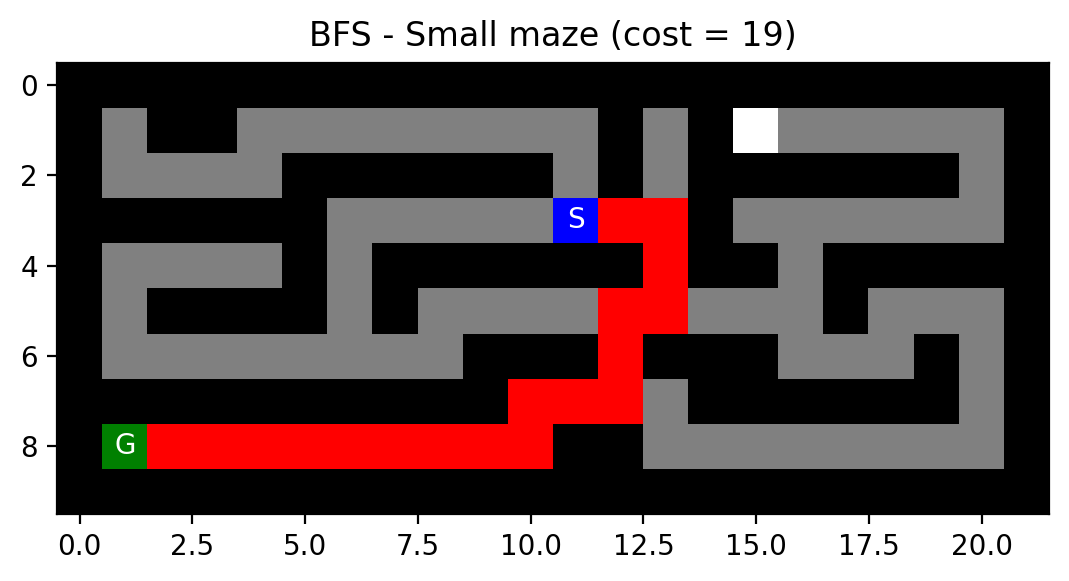

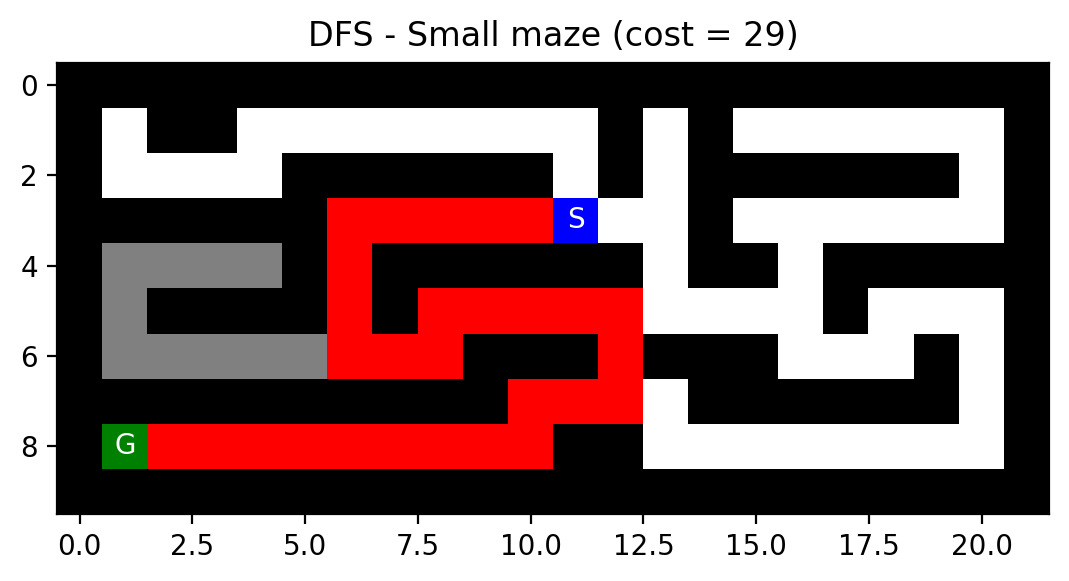

=== Mê cung Medium (18x36) ===


,Path cost,Nút mở rộng,Max depth,Max frontier,Thời gian (ms)
Thuật toán,,,,,
BFS,68,267,68,9,0.699
DFS,152,153,152,8,0.770


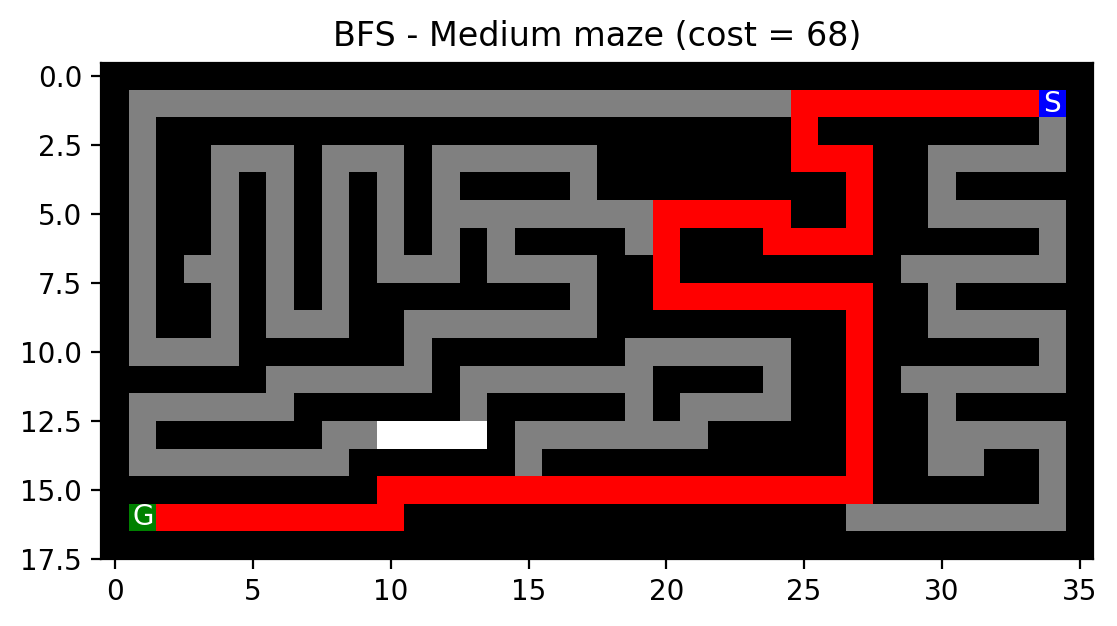

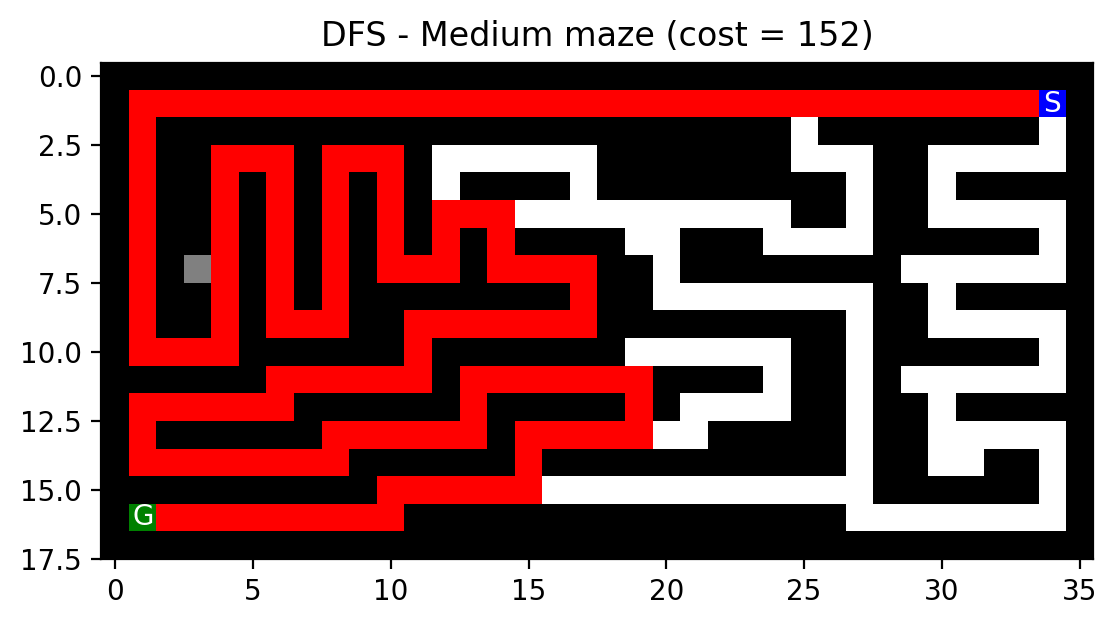

=== Mê cung Large (37x37) ===


,Path cost,Nút mở rộng,Max depth,Max frontier,Thời gian (ms)
Thuật toán,,,,,
BFS,210,618,210,8,1.652
DFS,210,337,214,38,2.768


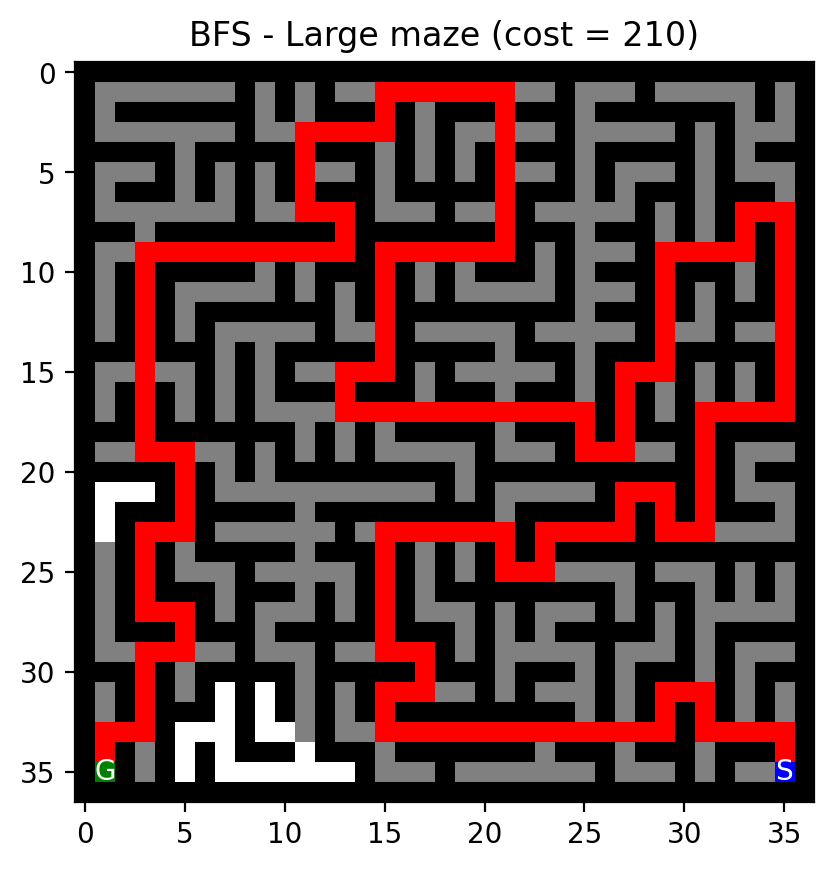

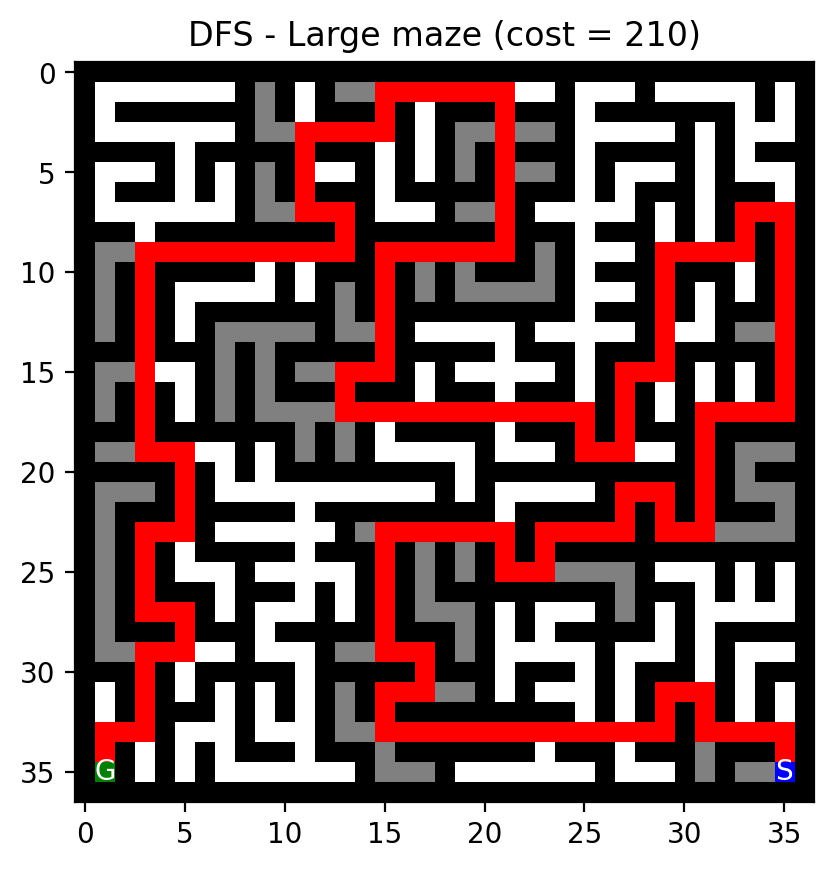

In [57]:
import pandas as pd
from IPython.display import display

def show_solution(maze, node, stats, title=None):
    """Vẽ lời giải lên một BẢN SAO của mê cung (không sửa maze gốc):
    '.' = ô đã duyệt, 'P' = các ô trên đường đi cuối cùng; S và G giữ nguyên."""
    m = maze.copy()
    for pos in stats["visited"]:
        if m[pos] == " ":
            m[pos] = "."
    for n in node.get_path_from_root():
        if m[n.pos] in (" ", "."):
            m[n.pos] = "P"
    mh.show_maze(m, title=title)

# Các mê cung dùng trong thực nghiệm (muốn thêm mê cung khác chỉ cần thêm vào dict này)
maze_files = {"Small": "small_maze.txt",
              "Medium": "medium_maze.txt",
              "Large": "large_maze.txt"}
algorithms = {"BFS": bfs, "DFS": dfs}

for maze_name, filename in maze_files.items():
    with open(filename, "r") as f:
        maze = mh.parse_maze(f.read())
    start = mh.find_pos(maze, what="S")
    goal = mh.find_pos(maze, what="G")

    rows, solutions = [], {}
    for algo_name, algo in algorithms.items():
        node, st = algo(maze, start, goal)
        if node is None:                      # không tìm thấy đường đi
            rows.append({"Thuật toán": algo_name, "Path cost": "N/A",
                         "Nút mở rộng": "N/A", "Max depth": "N/A",
                         "Max frontier": "N/A", "Thời gian (ms)": "N/A"})
            continue
        solutions[algo_name] = (node, st)
        rows.append({"Thuật toán": algo_name, "Path cost": st["cost"],
                     "Nút mở rộng": st["expanded"], "Max depth": st["max_depth"],
                     "Max frontier": st["max_frontier"],
                     "Thời gian (ms)": round(st["time"] * 1000, 3)})

    print(f"=== Mê cung {maze_name} ({maze.shape[0]}x{maze.shape[1]}) ===")
    display(pd.DataFrame(rows).set_index("Thuật toán"))
    for algo_name, (node, st) in solutions.items():
        show_solution(maze, node, st,
                      title=f"{algo_name} - {maze_name} maze (cost = {st['cost']})")

**Cách đọc kết quả.** BFS luôn cho path cost nhỏ nhất vì mọi bước có cost 1. DFS có thể cho path cost lớn hơn (hoặc bằng) vì nó đi theo nhánh đầu tiên tìm thấy đích, không đảm bảo ngắn nhất. Ở hình của BFS, vùng `.` thường rộng hơn vì BFS tìm theo lớp; ở hình của DFS, vùng `.` thường hẹp hơn nhưng đường `P` có thể vòng vèo. Lưu ý `visited` của BFS là tập `reached` (gồm cả ô đã được đưa vào frontier), còn của DFS là các ô đã được mở rộng.

Complete the following table for each maze.

__Small maze__

| algorithm | path cost | # of nodes expanded | max tree depth | max # of nodes in memory | max frontier size |
|-----------|-----------|----------------|----------------|---------------|-------------------|
| BFS       |           |                |                |               |                   |
| DFS       |           |                |                |               |                   |
| GBS       |           |                |                |               |                   |
| A*        |           |                |                |               |                   |

__Medium Maze__

...

Present the results as using charts (see [Python Code Examples/charts and tables](../HOWTOs/charts_and_tables.ipynb)). 

Path cost  Nút mở rộng  Max depth  Max frontier  \
Mê cung Thuật toán                                                    
Small   BFS                19           90         19             9   
        DFS                29           39         29             5   
Medium  BFS                68          267         68             9   
        DFS               152          153        152             8   
Large   BFS               210          618        210             8   
        DFS               210          337        214            38   

                    Thời gian (ms)  
Mê cung Thuật toán                  
Small   BFS                  0.221  
        DFS                  0.120  
Medium  BFS                  0.675  
        DFS                  0.745  
Large   BFS                  1.507  
        DFS                  2.038

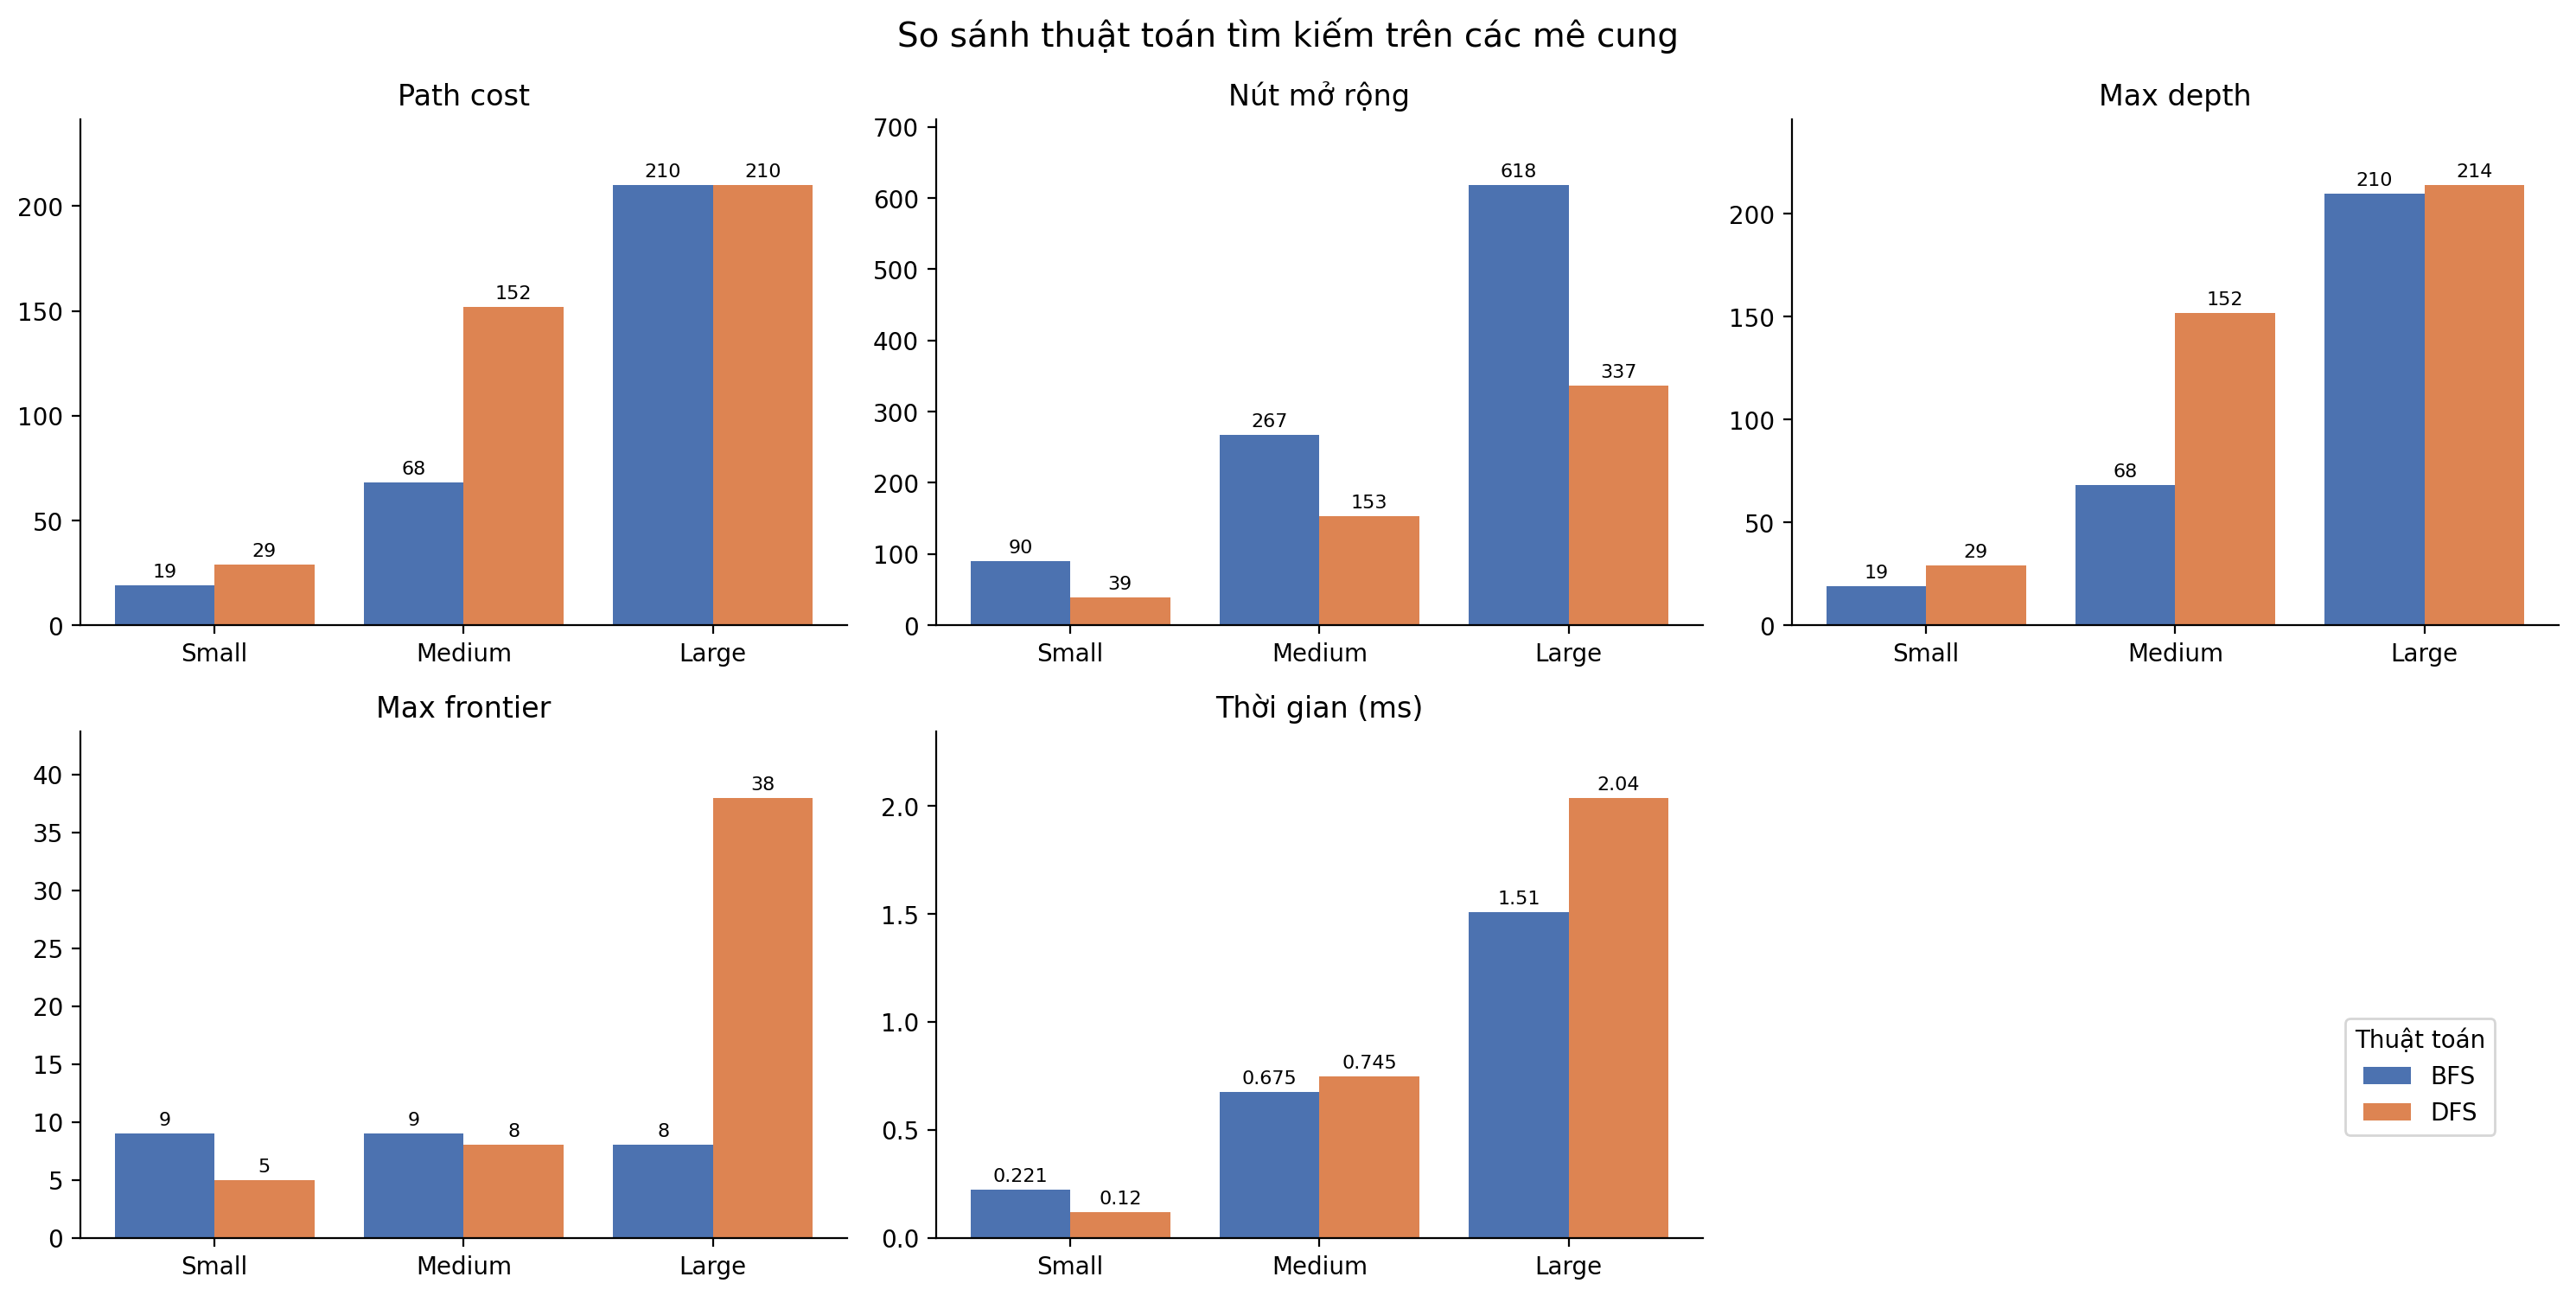

In [58]:
import matplotlib.pyplot as plt

def run_benchmark(maze_files, algorithms, repeats=5):
    '''Chạy từng thuật toán trên từng mê cung, trả về DataFrame số liệu.
    Thời gian lấy giá trị nhỏ nhất trong `repeats` lần chạy để giảm nhiễu.'''
    rows = []
    for maze_name, filename in maze_files.items():
        with open(filename) as f:
            maze = mh.parse_maze(f.read())
        start, goal = mh.find_pos(maze, "S"), mh.find_pos(maze, "G")
        for algo_name, algo in algorithms.items():
            node, st = algo(maze, start, goal)
            if node is None:                       # không có đường đi: bỏ qua
                continue
            times = [st["time"]] + [algo(maze, start, goal)[1]["time"] for _ in range(repeats - 1)]
            rows.append({"Mê cung": maze_name, "Thuật toán": algo_name,
                         "Path cost": st["cost"], "Nút mở rộng": st["expanded"],
                         "Max depth": st["max_depth"], "Max frontier": st["max_frontier"],
                         "Thời gian (ms)": min(times) * 1000})
    return pd.DataFrame(rows)

def plot_comparison(results, metrics, colors=None):
    '''Biểu đồ cột nhóm: mỗi ô là một chỉ số, nhóm cột theo mê cung, màu theo thuật toán.
    Tự mở rộng khi `algorithms` có thêm thuật toán (GBFS, A*, ...).'''
    colors = colors or {"BFS": "#4C72B0", "DFS": "#DD8452", "GBFS": "#55A868", "A*": "#C44E52"}
    mazes = list(dict.fromkeys(results["Mê cung"]))
    algos = list(dict.fromkeys(results["Thuật toán"]))
    width = 0.8 / len(algos)

    ncols = 3
    nrows = -(-len(metrics) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.8 * nrows), squeeze=False)
    for ax, metric in zip(axes.flat, metrics):
        for i, algo in enumerate(algos):
            vals = [results[(results["Mê cung"] == mz) & (results["Thuật toán"] == algo)][metric].iloc[0]
                    for mz in mazes]
            xs = [k + (i - (len(algos) - 1) / 2) * width for k in range(len(mazes))]
            bars = ax.bar(xs, vals, width, label=algo, color=colors.get(algo))
            ax.bar_label(bars, fmt="%.3g", fontsize=8, padding=2)
        ax.set_xticks(range(len(mazes)))
        ax.set_xticklabels(mazes)
        ax.set_title(metric)
        ax.margins(y=0.15)
        ax.spines[["top", "right"]].set_visible(False)
    for ax in list(axes.flat)[len(metrics):]:       # ẩn ô thừa
        ax.axis("off")
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower right", bbox_to_anchor=(0.97, 0.12), title="Thuật toán")
    fig.suptitle("So sánh thuật toán tìm kiếm trên các mê cung", fontsize=14)
    fig.tight_layout()
    plt.show()

results = run_benchmark(maze_files, algorithms)
display(results.set_index(["Mê cung", "Thuật toán"]).round(3))
plot_comparison(results, ["Path cost", "Nút mở rộng", "Max depth", "Max frontier", "Thời gian (ms)"])

Discuss the most important lessons you have learned from implementing the different search strategies. 

**Nhận xét từ biểu đồ (BFS và DFS).** 

* **Path cost:** BFS luôn nhỏ nhất (19, 68, 210). DFS dài hơn nhiều ở small (29) và medium (152) và chỉ bằng BFS ở large (210).
* **Nút mở rộng:** DFS mở rộng ít nút hơn BFS ở cả ba mê cung (39 so với 90, 153 so với 267, 337 so với 618), vì BFS duyệt toàn bộ mọi ô gần xuất phát hơn đích còn DFS đi thẳng một nhánh. Ít nút hơn **không** có nghĩa là lời giải tốt hơn.
* **Max depth:** bằng path cost với BFS; DFS thì bằng hoặc lớn hơn path cost (ở large là 214 so với cost 210) vì nó từng đi vào nhánh sâu hơn đường cuối cùng.
* **Max frontier:** ở small và medium DFS nhỏ hơn BFS, nhưng ở large DFS lại lớn hơn (38 so với 8). Cột này chỉ đo `frontier`; BFS còn giữ thêm tập `reached`, nên không thể kết luận DFS luôn tốn ít bộ nhớ hơn chỉ từ cột này.
* **Thời gian:** chỉ ở mức vài mili-giây, khá nhiễu, nên chỉ dùng để tham khảo chứ không rút ra kết luận mạnh.

## Advanced task: IDS and Multiple goals

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### IDS 
Implement IDS (iterative deepening search) using your DFS implementation. Test IDS on the mazes above. You may run into some issues with mazes with open spaces. If you cannot resolve the issues, then report and discuss what causes the problems.

In [60]:
# Your code/answer goes here

### Multiple Goals 
Create a few mazes with multiple goals by adding one or two more goals to the medium size maze. The agent is done when it finds one of the goals.
Solve the maze with your implementations for DFS, BFS, and IDS. Run experiments to show which implementations find the optimal solution and which do not. Discuss why that is the case.

In [61]:
# Your code/answer goes here

## More Advanced Problems to Think About (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Intersection as States
Instead of defining each square as a state, use only intersections as states. Now the storage requirement is reduced, but the path length between two intersections can be different. If we use total path length measured as the number of squares as path cost, how can we make sure that BFS and iterative deepening search is optimal? Change the code to do so.

In [62]:
# Your code/answer goes here

### Weighted A* search
Modify your A* search to add weights (see text book) and explore how different weights influence the result.

In [63]:
# Your code/answer goes here

### Unknown Maze
What happens if the agent does not know the layout of the maze in advance? This means that the agent faces an unknown environment, where it does not know the transition function. How does the environment look then (PEAS description)? How would you implement a rational agent to solve the maze? What if the agent still has a GPS device to tell the distance to the goal?

In [64]:
# Your code/answer goes here